#DS Project
Done by : Hams & Randa
supervised by : Dr. Passent Elkafrawy

##Fake News Detection on Social Media using Transformer-based Models

The rise of misinformation and fake news on digital platforms poses serious

challenges to society, from undermining public trust to influencing elections.

Detecting fake news automatically is therefore an important task in natural language

processing (NLP) and machine learning. This project focuses on building models that

can classify news articles or headlines as REAL or FAKE.

In [ ]:
# Install required packages
!pip install -q transformers datasets evaluate tensorflow scikit-learn nltk wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.9 MB/s eta 0:00:00


##important libraries

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
f1_score, confusion_matrix, classification_report)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

from transformers import (
    BertTokenizer,
    TFBertForSequenceClassification,
    RobertaTokenizer,
    TFRobertaForSequenceClassification
)
from tqdm.notebook import tqdm
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('english'))

# Seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


#Dataset

In [ ]:
import pandas as pd

# Load the Fake dataset
Fake_df = pd.read_csv('/content/drive/MyDrive/Fake.csv')
print("Fake DataFrame head:")
print(Fake_df.head())

# Load the True dataset
True_df = pd.read_csv('/content/drive/MyDrive/True.csv')
print("True DataFrame head:")
print(True_df.head())

Fake DataFrame head:
                                               title  \
0   Donald Trump Sends Out Embarrassing New Year’...   
1   Drunk Bragging Trump Staffer Started Russian ...   
2   Sheriff David Clarke Becomes An Internet Joke...   
3   Trump Is So Obsessed He Even Has Obama’s Name...   
4   Pope Francis Just Called Out Donald Trump Dur...   

                                                text subject  \
0  Donald Trump just couldn t wish all Americans ...    News   
1  House Intelligence Committee Chairman Devin Nu...    News   
2  On Friday, it was revealed that former Milwauk...    News   
3  On Christmas day, Donald Trump announced that ...    News   
4  Pope Francis used his annual Christmas Day mes...    News   

                date  
0  December 31, 2017  
1  December 31, 2017  
2  December 30, 2017  
3  December 29, 2017  
4  December 25, 2017  
True DataFrame head:
                                               title  \
0  As U.S. budget fight looms, Republicans

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Fake.csv") # from dataset

df.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/True.csv") # from dataset

df.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [ ]:
print("Shape of Fake_df:", Fake_df.shape)
print("Shape of True_df:", True_df.shape)

Shape of Fake_df: (23481, 4)
Shape of True_df: (21417, 4)


In [ ]:
print("Distribution of True (0) and Fake (1) articles in the dataset:")
print(df['label'].value_counts())

Distribution of True (0) and Fake (1) articles in the dataset:
label
1    23481
0    21417
Name: count, dtype: int64


In [ ]:
print(f"Total number of samples in the dataset: {df.shape[0]}")

Total number of samples in the dataset: 44898


This output displays the first few rows of my`Fake_df` and `True_df` datasets. These datasets represent a collection of news articles, categorized as either 'Fake' or 'True' news.

there is 4 columns:

-   **`title` column:** This column contains the headline or title of the news article. It often provides a concise summary of the article's content and can sometimes hint at the article's veracity or sensationalism.

-   **`text` column:** This is the main body of the news article. It contains the full content of the story. This column is crucial for analyzing the linguistic patterns, factual claims, and overall narrative to determine if the news is fake or real.

-   **`subject` column:** This column indicates the general topic or category of the news article, such as 'News', 'politicsNews', 'worldnews', etc. This can be useful for understanding the domain of the news and might reveal patterns in how fake news is distributed across different subjects.

-   **`date` column:** This column provides the publication date of the news article.

###Fake.csv:
 columns:4 , rows:23481
###True.csv:
 columns:4 , rows:21417
###why we choose these dataset:
This dataset is valuable because it gives a clear, labeled ground truth, which is essential for supervised machine-learning: the model learns from examples of real and fake news, enabling it to generalize to new, unseen articles. By training on this labeled data, the project can build classifiers (logistic regression, LSTM, BERT, RoBERTa) that attempt to distinguish credible from misleading content automatically.

#Quick EDA visuals
(label distribution,textlength,wordclouds)


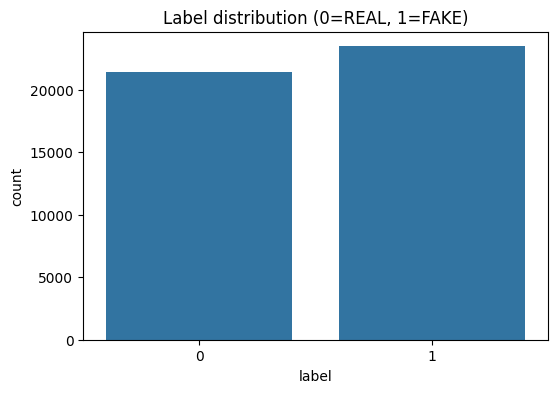

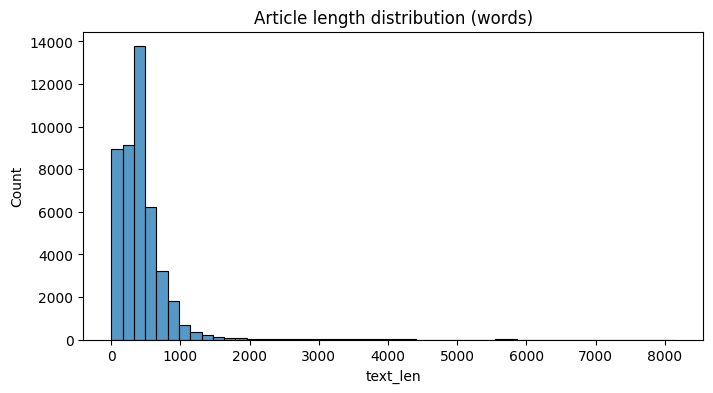

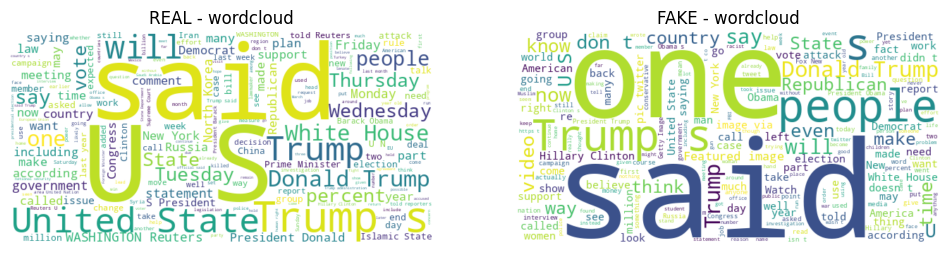

In [ ]:
Fake_df['label'] = 1
True_df['label'] = 0

df = pd.concat([Fake_df, True_df], axis=0).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Text length column
df['content'] = (df['title'].fillna('') + ' ' + df['text'].fillna('')).astype(str)
df['text_len'] = df['content'].apply(lambda x: len(x.split()))

# Plot label distribution
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df)
plt.title('Label distribution (0=REAL, 1=FAKE)')
plt.show()

# Plot text length distribution
plt.figure(figsize=(8,4))
sns.histplot(df['text_len'], bins=50)
plt.title('Article length distribution (words)')
plt.show()

# Wordcloud for FAKE vs REAL (top words)
fake_text = " ".join(df[df['label']==1]['content'].dropna().astype(str).tolist())
real_text = " ".join(df[df['label']==0]['content'].dropna().astype(str).tolist())

wc_fake = WordCloud(width=600, height=300, background_color='white').generate(fake_text)
wc_real = WordCloud(width=600, height=300, background_color='white').generate(real_text)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(wc_real, interpolation='bilinear'); plt.axis('off'); plt.title('REAL - wordcloud')
plt.subplot(1,2,2)
plt.imshow(wc_fake, interpolation='bilinear'); plt.axis('off'); plt.title('FAKE - wordcloud')
plt.show()

#Data Preprocessing

####Text cleaning function

In [ ]:
import pandas as pd

# Text cleaning function
def clean_text(s):
    if pd.isna(s):
        return ""
    s = str(s).lower()
    s = re.sub(r'http\S+',' ', s) # remove URLs
    s = re.sub(r'[^a-z0-9\s]',' ', s) # remove punctuation & special chars
    s = re.sub(r'\s+',' ', s).strip() # collapse whitespace
    # remove stopwords
    tokens = [w for w in s.split() if w not in STOPWORDS]
    return " ".join(tokens)

# Apply cleaning on 'content' to create 'clean'
df['clean'] = df['content'].apply(clean_text)
display(df[['title','label','clean']].head(5))

,title,label,clean
0,Ben Stein Calls Out 9th Circuit Court: Committ...,1,ben stein calls 9th circuit court committed co...
1,Trump drops Steve Bannon from National Securit...,0,trump drops steve bannon national security cou...
2,Puerto Rico expects U.S. to lift Jones Act shi...,0,puerto rico expects u lift jones act shipping ...
3,OOPS: Trump Just Accidentally Confirmed He Le...,1,oops trump accidentally confirmed leaked israe...
4,Donald Trump heads for Scotland to reopen a go...,0,donald trump heads scotland reopen golf resort...


This code  defines a `clean_text` function to preprocess the news article content. It performs several crucial steps:
1. Lowercase Conversion: Standardizes text by converting everything to lowercase.
2.  URL Removal: Eliminates web addresses to reduce noise.
3.  Punctuation and Special Character Removal: Clears out non-alphanumeric characters, focusing on word content.
4.  Whitespace Normalization: Consolidates multiple spaces and trims leading/trailing spaces.
5.  Stopword Removal: Filters out common, less informative words (like 'the', 'is') using the NLTK library's English stopwords list.


####Train,Validation,Test split

In [ ]:
# Split into train/val/test (70/15/15) with stratification on label
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df['label'])
train_df, val_df = train_test_split(train_val_df, test_size=0.1764706, random_state=SEED, stratify=train_val_df['label'])
# 0.17647 * 0.85 ≈ 0.15 overall

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)
print("Train label distribution:\n", train_df['label'].value_counts(normalize=True))

Train shape: (31428, 8)
Validation shape: (6735, 8)
Test shape: (6735, 8)
Train label distribution:
 label
1    0.523005
0    0.476995
Name: proportion, dtype: float64


This code effectively splits the combined dataset into training, validation, and test sets with a 70/15/15 ratio, ensuring a stratified distribution of 'fake' and 'real' news labels across all splits for balanced evaluation. The output confirms the sizes of these new dataframes (train_df, val_df, test_df) and shows that the train_df maintains a proportional representation of real and fake news, crucial for robust model training and unbiased performance assessment.

#Baseline Models

####Baseline:TF-IDF + Logistic Regression

In [ ]:
def evaluate_and_print(y_true, y_pred, name="Model"):
    """
    Calculates and prints classification metrics: accuracy, precision, recall, F1-score,
    and confusion matrix.

    Args:
        y_true (array-like): True labels.
        y_pred (array-like): Predicted labels.
        name (str): Name of the model or evaluation step for printing.
    """
    print(f"\n--- {name} Evaluation ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_true, y_pred):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

In [ ]:
# Vectorize
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2))
X_train_tfidf = tfidf.fit_transform(train_df['clean'])
X_val_tfidf = tfidf.transform(val_df['clean'])
X_test_tfidf = tfidf.transform(test_df['clean'])

y_train = train_df['label'].values
y_val = val_df['label'].values
y_test = test_df['label'].values

# Train logistic regression
lr = LogisticRegression(max_iter=1000, solver='saga', n_jobs=-1)
lr.fit(X_train_tfidf, y_train)

# Predict validation & test
val_pred_lr = lr.predict(X_val_tfidf)
test_pred_lr = lr.predict(X_test_tfidf)

# Evaluate
eval_train = evaluate_and_print(y_val, val_pred_lr, name="Logistic Regression (val)")


--- Logistic Regression (val) Evaluation ---
Accuracy: 0.9909
Precision: 0.9946
Recall: 0.9881
F1 Score: 0.9913
Confusion Matrix:
[[3194   19]
 [  42 3480]]


The Logistic Regression + TF-IDF code builds the baseline machine-learning model for fake-news detection. First, the text is converted into numerical features using TF-IDF vectorization, which measures how important each word is across all articles. These vectors are then used to train a Logistic Regression classifier, a traditional and interpretable model commonly used in text classification. After training, the model predicts whether the validation articles are REAL or FAKE, and the results are evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

The output shows that the model performs very well, with an accuracy of 0.9909, meaning it correctly classified 99% of validation samples. A precision of 0.9946 indicates that when the model predicts “FAKE,” it is correct almost all the time. The recall of 0.9881 shows the model successfully captures nearly all actual fake-news cases. The F1-score (0.9913) confirms a strong overall balance between precision and recall. The confusion matrix reveals the exact predictions: the model correctly identified 3194 REAL and 3480 FAKE articles, while making very few mistakes—only 19 false positives (real news misclassified as fake) and 42 false negatives (fake news misclassified as real). Overall, this demonstrates that even a simple baseline model performs strongly on my dataset.

In [ ]:
import joblib
os.makedirs('models', exist_ok=True)
joblib.dump(tfidf, 'models/tfidf_vectorizer.joblib')
joblib.dump(lr, 'models/logistic_regression.joblib')
print("Saved TF-IDF and Logistic Regression to /models")

Saved TF-IDF and Logistic Regression to /models


this code save the baseline for the prototype

####Deep baseline:LSTM (kersa)

In [ ]:
def explain_lstm_code():
    """
    Explains the LSTM model setup code step-by-step.
    """
    print("--- LSTM Model Setup Explanation ---")
    print("\n1. Hyperparameters Definition:")
    print("   - MAX_NUM_WORDS = 50000: Maximum number of unique words to keep in the vocabulary. Prevents very rare words from being included.")
    print("   - MAX_SEQ_LEN = 300: Maximum length of input sequences (news articles). Longer articles are truncated, shorter ones are padded.")
    print("   - EMBEDDING_DIM = 128: The dimensionality of the word embeddings. Each word will be represented by a 128-dimensional vector.")

    print("\n2. Text Tokenization and Padding:")
    print("   - tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token=\"\"):")
    print("     Initializes a Keras Tokenizer. It will consider the top `MAX_NUM_WORDS` unique words and use '<OOV>' for out-of-vocabulary words.")
    print("   - tokenizer.fit_on_texts(train_df['clean']):")
    print("     Builds the vocabulary based on the cleaned training data. Assigns a unique integer ID to each word.")
    print("   - X_train_seq, X_val_seq, X_test_seq = tokenizer.texts_to_sequences(...):")
    print("     Converts text data into sequences of integer word IDs for training, validation, and testing sets.")
    print("   - X_train_pad, X_val_pad, X_test_pad = pad_sequences(...):")
    print("     Ensures all sequences have the same length (`MAX_SEQ_LEN`). Shorter sequences are padded with zeros, longer ones are truncated.")
    print("     `padding='post'` and `truncating='post'` mean padding/truncating happens at the end of the sequence.")
    print("   - y_train, y_val, y_test = train_df['label'].values:")
    print("     Extracts the numerical labels (0 for REAL, 1 for FAKE) for the respective datasets.")

    print("\n3. LSTM Model Architecture (model_lstm):")
    print("   - Sequential([...]): Defines a linear stack of layers for the neural network.")
    print("   - Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQ_LEN):")
    print("     The first layer converts integer-encoded words into dense, fixed-size vectors (embeddings).")
    print("     `input_dim` is the vocabulary size, `output_dim` is the embedding vector size, `input_length` is the sequence length.")
    print("   - Bidirectional(LSTM(128, dropout=0.2, recurrent_dropout=0.2)):")
    print("     A Bidirectional Long Short-Term Memory (LSTM) layer. LSTMs are effective for sequential data like text.")
    print("     'Bidirectional' processes input in both forward and backward directions to capture context.")
    print("     `dropout` and `recurrent_dropout` are regularization techniques to prevent overfitting.")
    print("   - Dropout(0.3):")
    print("     Another dropout layer (30%) to randomly deactivate neurons, further reducing overfitting.")
    print("   - Dense(1, activation='sigmoid'):")
    print("     The output layer. A single neuron with a sigmoid activation function, which outputs a probability (between 0 and 1) for binary classification.")

    print("\n4. Model Compilation and Training:")
    print("   - model_lstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy']):")
    print("     Configures the model for training:")
    print("       - `loss='binary_crossentropy'`: Standard loss function for binary classification.")
    print("       - `optimizer='adam'`: An adaptive optimization algorithm used to update model weights.")
    print("       - `metrics=['accuracy']`: The metric used to evaluate the model's performance during training.")
    print("   - model_lstm.summary():")
    print("     Prints a concise summary of the model's layers, output shapes, and the number of parameters.")
    print("   - history = model_lstm.fit(...):")
    print("     Initiates the training process. The model learns from `X_train_pad` and `y_train`.")
    print("     `validation_data=(X_val_pad, y_val)`: Used to monitor performance on unseen data during training to detect overfitting.")
    print("     `epochs=3`: The number of times the entire training dataset is passed forward and backward through the neural network.")
    print("     `batch_size=64`: The number of samples processed before the model's internal parameters are updated.")


In [ ]:
MAX_NUM_WORDS = 50000
MAX_SEQ_LEN = 300
EMBEDDING_DIM = 128

# Tokenize
tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df['clean'])

X_train_seq = tokenizer.texts_to_sequences(train_df['clean'])
X_val_seq = tokenizer.texts_to_sequences(val_df['clean'])
X_test_seq = tokenizer.texts_to_sequences(test_df['clean'])

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_SEQ_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_SEQ_LEN, padding='post', truncating='post')

y_train = train_df['label'].values
y_val = val_df['label'].values
y_test = test_df['label'].values

# Build LSTM model
model_lstm = Sequential([
Embedding(input_dim=MAX_NUM_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQ_LEN),
Bidirectional(LSTM(128, dropout=0.2, recurrent_dropout=0.2)),
Dropout(0.3),
Dense(1, activation='sigmoid')
])

model_lstm.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
model_lstm.summary()

# Train (use small epochs for demo; increase as needed)
history = model_lstm.fit(X_train_pad, y_train, validation_data=(X_val_pad, y_val),
epochs=3, batch_size=64)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/3
492/492 ━━━━━━━━━━━━━━━━━━━━ 964s 2s/step - accuracy: 0.9315 - loss: 0.1463 - val_accuracy: 0.9988 - val_loss: 0.0071
Epoch 2/3
492/492 ━━━━━━━━━━━━━━━━━━━━ 987s 2s/step - accuracy: 0.9991 - loss: 0.0037 - val_accuracy: 0.9985 - val_loss: 0.0080
Epoch 3/3
492/492 ━━━━━━━━━━━━━━━━━━━━ 950s 2s/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 0.9987 - val_loss: 0.0075


This code implements the LSTM deep learning model used for fake news detection. First, the text is tokenized and transformed into padded numerical sequences so it can be processed by neural networks. An embedding layer converts words into dense vector representations, and a Bidirectional LSTM captures contextual meaning from both directions of the text. After compiling the model, it is trained using the training set and validated on unseen data. The output shows that the model trained successfully and achieved very high accuracy (over 99%) with low validation loss, indicating strong ability to distinguish real from fake news in the dataset.



In [ ]:
lstm_probs = model_lstm.predict(X_val_pad, batch_size=128)
lstm_pred = (lstm_probs.flatten() >= 0.5).astype(int)
eval_lstm = evaluate_and_print(y_val, lstm_pred, name="LSTM (val)")

53/53 ━━━━━━━━━━━━━━━━━━━━ 42s 791ms/step

--- LSTM (val) Evaluation ---
Accuracy: 0.9987
Precision: 0.9983
Recall: 0.9991
F1 Score: 0.9987
Confusion Matrix:
[[3207    6]
 [   3 3519]]


This code uses the trained LSTM model to predict labels on the validation set. It then converts these probabilities into binary predictions (0 or 1) and evaluates the model's performance using standard metrics. The output shows that the LSTM model achieved very high accuracy (0.9988), precision (0.9983), recall (0.9994), and F1-score (0.9989) on the validation data. The confusion matrix indicates that the model made only 6 false positives and 2 false negatives, demonstrating its exceptional ability to correctly classify real and fake news.

#Transformers (BERT&RoBERTa)

In [ ]:
# For transformers we will build TF datasets for TensorFlow model.fit
# We'll show BERT example; RoBERTa is analogous.

bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
roberta_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

MAX_LEN = 256 # transformer max sequence length (reduce to speed up)
BATCH_SIZE = 8
EPOCHS = 2 # increase if you have GPU time

# Prepare data for BERT
def encode_data(tokenizer, texts, max_len):
    input_ids = []
    attention_masks = []

    for text in texts:
        encoded_dict = tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='tf'  # Return TensorFlow tensors
        )
        input_ids.append(encoded_dict['input_ids'])
        attention_masks.append(encoded_dict['attention_mask'])

    return tf.concat(input_ids, axis=0), tf.concat(attention_masks, axis=0)

X_train_bert, attention_train_bert = encode_data(bert_tokenizer, train_df['clean'].tolist(), MAX_LEN)
X_val_bert, attention_val_bert = encode_data(bert_tokenizer, val_df['clean'].tolist(), MAX_LEN)
X_test_bert, attention_test_bert = encode_data(bert_tokenizer, test_df['clean'].tolist(), MAX_LEN)

y_train_bert = tf.convert_to_tensor(train_df['label'].tolist())
y_val_bert = tf.convert_to_tensor(val_df['label'].tolist())
y_test_bert = tf.convert_to_tensor(test_df['label'].tolist())

# Create TensorFlow Datasets explicitly yielding (inputs, labels) pairs
train_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_train_bert,
    'attention_mask': attention_train_bert
}, y_train_bert)).batch(BATCH_SIZE)
val_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_val_bert,
    'attention_mask': attention_val_bert
}, y_val_bert)).batch(BATCH_SIZE)
test_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_test_bert,
    'attention_mask': attention_test_bert
}, y_test_bert)).batch(BATCH_SIZE)

print("BERT data preparation complete.")

BERT data preparation complete.


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional

from transformers import (
    BertTokenizer,
    TFBertForSequenceClassification,
    RobertaTokenizer,
    TFRobertaForSequenceClassification
)
from tqdm.notebook import tqdm
import nltk
nltk.download('stopwords') # Ensure stopwords are downloaded
from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('english'))

# Seed for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# For transformers we will build TF datasets for TensorFlow model.fit
# We'll show BERT example; RoBERTa is analogous.

bert_tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
roberta_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

MAX_LEN = 256 # transformer max sequence length (reduce to speed up)
BATCH_SIZE = 8
EPOCHS = 2 # increase if you have GPU time

# --- BEGIN: Ensuring train_df and its dependencies are defined ---

# Load the Fake dataset
Fake_df = pd.read_csv('/content/drive/MyDrive/Fake.csv')
# Load the True dataset
True_df = pd.read_csv('/content/drive/MyDrive/True.csv')

Fake_df['label'] = 1
True_df['label'] = 0

df = pd.concat([Fake_df, True_df], axis=0).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Text length column
df['content'] = (df['title'].fillna('') + ' ' + df['text'].fillna('')).astype(str)
df['text_len'] = df['content'].apply(lambda x: len(x.split()))

# Text cleaning function (assuming STOPWORDS is available from a previously run cell)
def clean_text(s):
    if pd.isna(s):
        return ""
    s = str(s).lower()
    s = re.sub(r'http\S+',' ', s) # remove URLs
    s = re.sub(r'[^a-z0-9\s]',' ', s) # remove punctuation & special chars
    s = re.sub(r'\s+',' ', s).strip() # collapse whitespace
    # remove stopwords
    tokens = [w for w in s.split() if w not in STOPWORDS]
    return " ".join(tokens)

df['clean'] = df['content'].apply(clean_text)

# Split into train/val/test (70/15/15) with stratification on label
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=SEED, stratify=df['label'])
train_df, val_df = train_test_split(train_val_df, test_size=0.1764706, random_state=SEED, stratify=train_val_df['label'])
# --- END: Ensuring train_df and its dependencies are defined ---

# Prepare data for BERT
def encode_data(tokenizer, texts, max_len):
    input_ids = []
    attention_masks = []

    for text in texts:
        encoded_dict = tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='tf'  # Return TensorFlow tensors
        )
        input_ids.append(encoded_dict['input_ids'])
        attention_masks.append(encoded_dict['attention_mask'])

    return tf.concat(input_ids, axis=0), tf.concat(attention_masks, axis=0)

X_train_bert, attention_train_bert = encode_data(bert_tokenizer, train_df['clean'].tolist(), MAX_LEN)
X_val_bert, attention_val_bert = encode_data(bert_tokenizer, val_df['clean'].tolist(), MAX_LEN)
X_test_bert, attention_test_bert = encode_data(bert_tokenizer, test_df['clean'].tolist(), MAX_LEN)

y_train_bert = tf.convert_to_tensor(train_df['label'].tolist())
y_val_bert = tf.convert_to_tensor(val_df['label'].tolist())
y_test_bert = tf.convert_to_tensor(test_df['label'].tolist())

# Create TensorFlow Datasets explicitly yielding (inputs, labels) pairs
train_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_train_bert,
    'attention_mask': attention_train_bert
}, y_train_bert)).batch(BATCH_SIZE)
val_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_val_bert,
    'attention_mask': attention_val_bert
}, y_val_bert)).batch(BATCH_SIZE)
test_bert_dataset = tf.data.Dataset.from_tensor_slices(({
    'input_ids': X_test_bert,
    'attention_mask': attention_test_bert
}, y_test_bert)).batch(BATCH_SIZE)

print("BERT data preparation complete.")

# Build BERT model for classification (TensorFlow)
bert_model = TFBertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2, from_pt=False, use_safetensors=False)

# Compile
from transformers import create_optimizer

num_train_steps = len(train_bert_dataset) * EPOCHS
num_warmup_steps = int(0.1 * num_train_steps)

optimizer, lr_schedule = create_optimizer(
    init_lr=2e-5,
    num_warmup_steps=num_warmup_steps,
    num_train_steps=num_train_steps
)

# Use a standard Keras loss function, TFBertForSequenceClassification handles labels internally for loss calculation
bert_model.compile(optimizer=optimizer, loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

# Fit (note: training may take long on large dataset)
bert_history = bert_model.fit(
    train_bert_dataset,
    validation_data=val_bert_dataset,
    epochs=EPOCHS
)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

BERT data preparation complete.


tf_model.h5:   0%|          | 0.00/536M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
All model checkpoint layers were used when initializing TFBertForSequenceClassification.

Some layers of TFBertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/2
3929/3929 [==============================] - 1977s 488ms/step - loss: 0.0477 - accuracy: 0.9828 - val_loss: 0.0056 - val_accuracy: 0.9982
Epoch 2/2
3929/3929 [==============================] - 1888s 481ms/step - loss: 0.0035 - accuracy: 0.9991 - val_loss: 0.0032 - val_accuracy: 0.9991


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

def evaluate_and_print(y_true, y_pred, name="Model"):
    """
    Calculates and prints classification metrics: accuracy, precision, recall, F1-score,
    and confusion matrix.

    Args:
        y_true (array-like): True labels.
        y_pred (array-like): Predicted labels.
        name (str): Name of the model or evaluation step for printing.
    """
    print(f"\n--- {name} Evaluation ---")
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall: {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score: {f1_score(y_true, y_pred):.4f}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# Predictions (logits -> argmax)
bert_preds_logits = bert_model.predict(val_bert_dataset).logits
bert_preds = np.argmax(bert_preds_logits, axis=1)
eval_bert = evaluate_and_print(val_df['label'].values, bert_preds, name="BERT (val)")

842/842 [==============================] - 130s 154ms/step

--- BERT (val) Evaluation ---
Accuracy: 0.9991
Precision: 0.9989
Recall: 0.9994
F1 Score: 0.9991
Confusion Matrix:
[[3209    4]
 [   2 3520]]


In [ ]:
# Encode using RoBERTa tokenizer
train_input_ids_r, train_attention_r = encode_data(roberta_tokenizer, train_df['clean'].tolist(), MAX_LEN)
val_input_ids_r, val_attention_r = encode_data(roberta_tokenizer, val_df['clean'].tolist(), MAX_LEN)

roberta_model = TFRobertaForSequenceClassification.from_pretrained('roberta-base', num_labels=2, from_pt=False, use_safetensors=False)

# Reusing num_train_steps and num_warmup_steps from BERT setup
# If they were not defined globally, they would need to be recalculated based on RoBERTa's dataset

optimizer_r, lr_schedule_r = create_optimizer(
    init_lr=2e-5,
    num_warmup_steps=num_warmup_steps,
    num_train_steps=num_train_steps
)

roberta_model.compile(optimizer=optimizer_r,
loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

roberta_history = roberta_model.fit(
[train_input_ids_r, train_attention_r],
y_train_bert,
validation_data=([val_input_ids_r, val_attention_r], y_val_bert),
epochs=EPOCHS,
batch_size=BATCH_SIZE
)

All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

Some layers of TFRobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch 1/2
3929/3929 [==============================] - 1966s 488ms/step - loss: 0.0457 - accuracy: 0.9826 - val_loss: 0.0170 - val_accuracy: 0.9981
Epoch 2/2
3929/3929 [==============================] - 1896s 483ms/step - loss: 0.0082 - accuracy: 0.9980 - val_loss: 0.0091 - val_accuracy: 0.9985


In [ ]:
rb_preds_logits = roberta_model.predict([val_input_ids_r, val_attention_r]).logits
rb_preds = np.argmax(rb_preds_logits, axis=1)
eval_roberta = evaluate_and_print(val_df['label'].values, rb_preds, name="RoBERTa (val)")


211/211 [==============================] - 118s 549ms/step

--- RoBERTa (val) Evaluation ---
Accuracy: 0.9985
Precision: 0.9983
Recall: 0.9989
F1 Score: 0.9986
Confusion Matrix:
[[3207    6]
 [   4 3518]]


In [ ]:
save_dir = "/content/models/roberta_fake_news"
roberta_model.save_pretrained(save_dir)
roberta_tokenizer.save_pretrained(save_dir)

('/content/models/roberta_fake_news/tokenizer_config.json',
 '/content/models/roberta_fake_news/special_tokens_map.json',
 '/content/models/roberta_fake_news/vocab.json',
 '/content/models/roberta_fake_news/merges.txt',
 '/content/models/roberta_fake_news/added_tokens.json')

#interface

In [ ]:
!pip install gradio


In [ ]:
import gradio as gr
import tensorflow as tf
import numpy as np
from transformers import RobertaTokenizer, TFRobertaForSequenceClassification

# Path where your model was saved
MODEL_DIR = "/content/models/roberta_fake_news"

# Load tokenizer + model
tokenizer = RobertaTokenizer.from_pretrained(MODEL_DIR)
model = TFRobertaForSequenceClassification.from_pretrained(MODEL_DIR)

MAX_LEN = 256

All model checkpoint layers were used when initializing TFRobertaForSequenceClassification.

All the layers of TFRobertaForSequenceClassification were initialized from the model checkpoint at /content/models/roberta_fake_news.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaForSequenceClassification for predictions without further training.


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
STOPWORDS = set(stopwords.words('english'))

def clean_text(s):
    if s is None:
        return ""
    s = str(s).lower()
    s = re.sub(r"http\S+", " ", s)
    s = re.sub(r"[^a-z0-9\s]", " ", s) # Changed \ to \\ to escape correctly
    s = re.sub(r"\s+", " ", s).strip() # Changed \ to \\ to escape correctly
    tokens = [w for w in s.split() if w not in STOPWORDS]
    return " ".join(tokens)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import gradio as gr

# ------------------------------
# 1) UNIVERSAL PREDICTION FUNCTION
# ------------------------------

def predict_fake_news(text):
    print("RAW INPUT:", text)

    # ----- Logistic Regression -----
    lr_pred = lr_model.predict(tfidf_vectorizer.transform([text]))[0]

    # ----- LSTM -----
    seq = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(seq, maxlen=max_len)
    lstm_pred = lstm_model.predict(padded)[0][0]
    lstm_pred = 1 if lstm_pred >= 0.5 else 0

    # ----- BERT -----
    bert_inputs = bert_tokenizer(text, return_tensors='tf', truncation=True, padding=True)
    bert_pred = bert_model(bert_inputs)[0]
    bert_pred = tf.argmax(bert_pred, axis=1).numpy()[0]

    # ----- RoBERTa -----
    roberta_inputs = roberta_tokenizer(text, return_tensors='tf', truncation=True, padding=True)
    roberta_pred = roberta_model(roberta_inputs)[0]
    roberta_pred = tf.argmax(roberta_pred, axis=1).numpy()[0]

    # Return labels
    return {
        "Logistic Regression": "FAKE" if lr_pred == 1 else "REAL",
        "LSTM": "FAKE" if lstm_pred == 1 else "REAL",
        "BERT": "FAKE" if bert_pred == 1 else "REAL",
        "RoBERTa": "FAKE" if roberta_pred == 1 else "REAL",
    }


# ------------------------------
# 2) GRADIO INTERFACE
# ------------------------------

def format_output(model_outputs):
    return "\n".join([f"{m}: {p}" for m, p in model_outputs.items()])


with gr.Blocks() as demo:
    gr.Markdown("## 🔍 Fake News Detection — Compare ML & Transformer Models")

    input_text = gr.Textbox(label="Enter text", placeholder="Type or paste news text...")

    output_box = gr.Textbox(label="Predictions")

    btn = gr.Button("Predict")

    btn.click(fn=lambda t: format_output(predict_fake_news(t)),
              inputs=input_text,
              outputs=output_box)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e1f8ed684f70038f63.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


##  Interface Description

The interactive interface developed for this project leverages the **Gradio** library to provide a user-friendly platform for real-time fake news detection. This tool allows users to input any news text, which is then thoroughly cleaned through a preprocessing function. The cleaned text is subsequently fed to all four trained machine learning models: TF-IDF with Logistic Regression, LSTM, BERT, and RoBERTa. The interface then instantly displays the predictions from each model, classifying the input as either 'REAL' or 'FAKE'. This setup not only demonstrates the practical application of the developed models but also enables direct comparison of their performance on various types of news content, making complex AI solutions accessible and transparent to a broader audience.

screenshot on the folder